# Cancer Risk Level Prediction (Low / Medium / High)

**Goal:** Use lifestyle and health factors to predict a person's cancer **Risk Level**.

**What this notebook does, step by step**
1. Load the data and check its quality
2. Find and remove a *leaky* column (a column that gives away the answer)
3. Explore the data (EDA)
4. Split the data. The test set stays untouched until the very end
5. Compare models fairly using cross-validation (only on training data)
6. Tune the best model with Optuna
7. Test the final model **once** on the test set
8. Adjust the High-risk threshold (catching High risk matters most)
9. Explain the model (feature importance)
10. Save the model and test a prediction

> **Note:** This dataset looks synthetic (artificially generated). This is a learning project, **not** a medical tool.

## 1. Imports and Settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import optuna

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, recall_score, accuracy_score, fbeta_score)

from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
DATA_PATH = "cancer-risk-factors.csv"   # change this if your file is in another folder

## 2. Load the Data

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (2000, 21)


,Patient_ID,Cancer_Type,Age,Gender,Smoking,Alcohol_Use,Obesity,Family_History,Diet_Red_Meat,Diet_Salted_Processed,...,Physical_Activity,Air_Pollution,Occupational_Hazards,BRCA_Mutation,H_Pylori_Infection,Calcium_Intake,Overall_Risk_Score,BMI,Physical_Activity_Level,Risk_Level
0,LU0000,Breast,68,0,7,2,8,0,5,3,...,4,6,3,1,0,0,0.398696,28.0,5,Medium
1,LU0001,Prostate,74,1,8,9,8,0,0,3,...,1,3,3,0,0,5,0.424299,25.4,9,Medium
2,LU0002,Skin,55,1,7,10,7,0,3,3,...,1,8,10,0,0,6,0.605082,28.6,2,Medium
3,LU0003,Colon,61,0,6,2,2,0,6,2,...,6,4,8,0,0,8,0.318449,32.1,7,Low
4,LU0004,Lung,67,1,10,7,4,0,6,3,...,9,10,9,0,0,5,0.524358,25.1,2,Medium


## 3. Data Quality Check

We check for missing values and duplicate rows before doing anything else.

In [3]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows      :", df.duplicated().sum())
print("Duplicate Patient_ID:", df["Patient_ID"].duplicated().sum())
df.describe().T[["min", "max", "mean"]].round(2)

Total missing values: 0
Duplicate rows      : 0
Duplicate Patient_ID: 0


,min,max,mean
Age,25.00,90.00,63.25
Gender,0.00,1.00,0.49
Smoking,0.00,10.00,5.16
Alcohol_Use,0.00,10.00,5.04
Obesity,0.00,10.00,5.97
Family_History,0.00,1.00,0.19
Diet_Red_Meat,0.00,10.00,5.19
Diet_Salted_Processed,0.00,10.00,4.56
Fruit_Veg_Intake,0.00,10.00,4.93
Physical_Activity,0.00,10.00,4.01


## 4. Leakage Check (Very Important)

**Data leakage** means a column contains information that gives away the answer, so the model looks great
but would fail in real life.

`Overall_Risk_Score` is a suspect. If `Risk_Level` was created from this score using cut-off values,
a model can just learn the cut-offs and reach ~100% accuracy without learning anything real.
Let us check: do the score ranges for Low, Medium and High overlap?

In [4]:
print(df.groupby("Risk_Level")["Overall_Risk_Score"].agg(["min", "max", "mean"]).round(3))

              min    max   mean
Risk_Level                     
High        0.661  0.852  0.700
Low         0.029  0.330  0.269
Medium      0.330  0.659  0.477


**How to read this:** if the ranges do **not** overlap (for example Low < 0.35, High > 0.6), then `Risk_Level` is just
`Overall_Risk_Score` with labels. In a real situation we would not know the score in advance, so we **drop it**.

We also drop:
- `Patient_ID`: it is only an identifier and has no meaning for prediction.
- `Cancer_Type`: it is a diagnosis-type label, not a risk factor. (Optional experiment for later: one-hot encode it and compare the scores.)

In [5]:
TARGET = "Risk_Level"
DROP_COLS = ["Patient_ID", "Cancer_Type", "Overall_Risk_Score"]

X = df.drop(columns=[TARGET] + DROP_COLS)
y_text = df[TARGET]

print("Features used:", X.shape[1])
print(list(X.columns))

Features used: 17
['Age', 'Gender', 'Smoking', 'Alcohol_Use', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution', 'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection', 'Calcium_Intake', 'BMI', 'Physical_Activity_Level']


## 5. Exploratory Data Analysis (EDA)

### 5.1 How balanced are the classes?

            Count  Percent
Risk_Level                
Medium       1574     78.7
Low           324     16.2
High          102      5.1


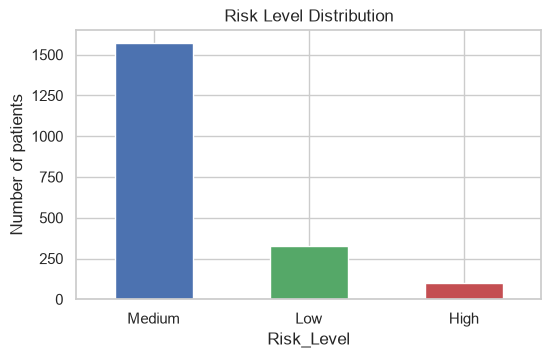

In [6]:
counts = y_text.value_counts()
print(pd.DataFrame({"Count": counts, "Percent": (counts / len(y_text) * 100).round(1)}))

counts.plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"], figsize=(6, 3.5))
plt.title("Risk Level Distribution")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
plt.show()

**Observation:** Most patients are *Medium*. *High* is only about 5%. The data is **imbalanced**, so plain accuracy is misleading
(a model that always says "Medium" would already get ~79% accuracy). That is why we use **macro-F1** and **High-class recall**.

### 5.2 Which features are related to each other?

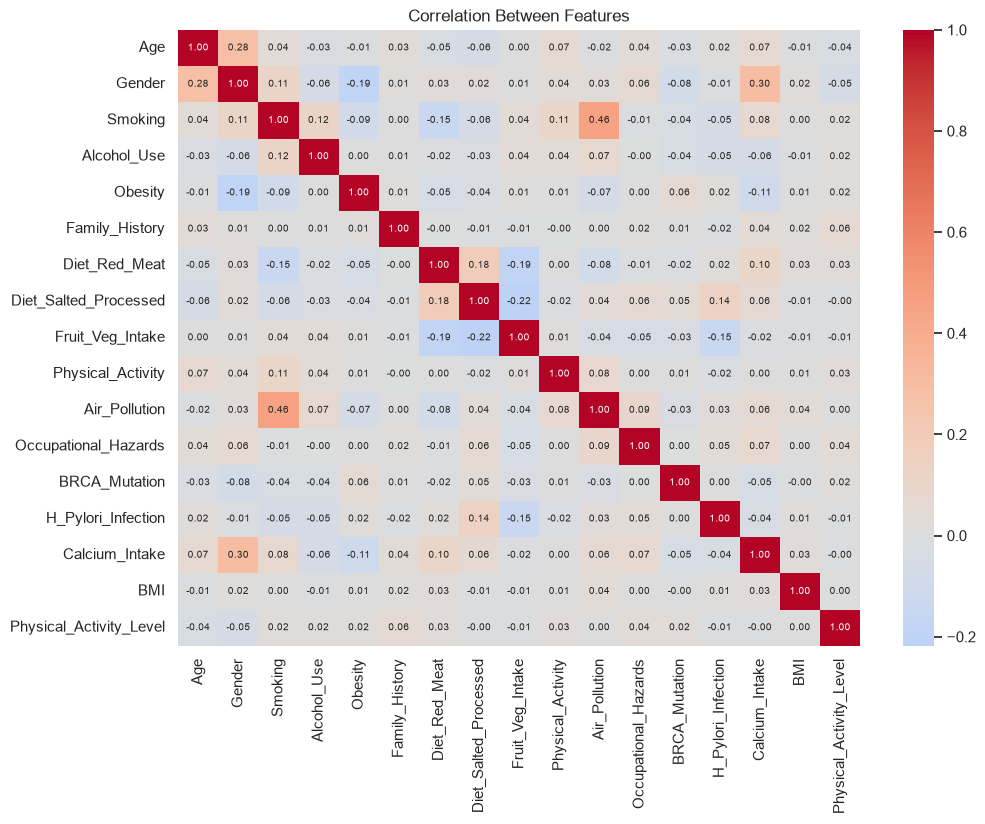

In [7]:
plt.figure(figsize=(11, 8))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation Between Features")
plt.show()

**What to look for:** pairs with a very high correlation (for example `Obesity` and `BMI`, or `Physical_Activity` and
`Physical_Activity_Level`) carry almost the same information. Tree models can handle this, but it is good to know.

### 5.3 Average feature value for each risk level

In [8]:
profile = X.groupby(y_text).mean().T[["Low", "Medium", "High"]].round(2)
profile["High minus Low"] = (profile["High"] - profile["Low"]).round(2)
profile.sort_values("High minus Low", ascending=False)

Risk_Level,Low,Medium,High,High minus Low
Air_Pollution,2.95,5.60,8.54,5.59
Smoking,2.85,5.48,7.52,4.67
Alcohol_Use,2.98,5.30,7.52,4.54
Diet_Salted_Processed,2.89,4.75,7.04,4.15
Occupational_Hazards,3.36,5.18,6.99,3.63
Diet_Red_Meat,3.97,5.30,7.36,3.39
Obesity,4.82,6.12,7.27,2.45
Physical_Activity,3.67,4.03,4.92,1.25
Calcium_Intake,3.65,3.98,4.32,0.67
BMI,25.81,26.26,26.23,0.42


**How to read this:** features with a big *High minus Low* gap are the ones that differ most between the risk groups.
(This shows a pattern in the data, it does not prove that a feature *causes* cancer.)

## 6. Train-Test Split

- 80% training, 20% test, **stratified** so each part keeps the same class ratio.
- The **test set is used only once, at the end**. All model choices below use only the training data.

In [9]:
le = LabelEncoder()
y = le.fit_transform(y_text)           # High=0, Low=1, Medium=2
CLASSES = list(le.classes_)
HIGH = CLASSES.index("High")
print("Class order:", CLASSES)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("High cases in test set:", (y_test == HIGH).sum(), "(very few, so test scores can jump a lot)")

Class order: ['High', 'Low', 'Medium']
Train: (1600, 17)  Test: (400, 17)
High cases in test set: 20 (very few, so test scores can jump a lot)


## 7. Fair Model Comparison (Cross-Validation on Training Data)

Instead of judging models on one lucky split, we use **repeated stratified 5-fold cross-validation**
(5 folds x 2 repeats = 10 mini-experiments per model) and report the average.

We compare these ways of handling the imbalance:

| Model | How it handles imbalance |
|---|---|
| Logistic Regression | `class_weight="balanced"` |
| Random Forest | `class_weight="balanced"` |
| Random Forest + SMOTE | creates synthetic High/Low samples (only inside each training fold) |
| XGBoost (plain) | nothing (baseline) |
| XGBoost + SMOTE | synthetic samples inside each training fold |
| XGBoost + class weights | gives rare classes more weight |

> Resampling like SMOTE is done **inside** each fold. Doing it before splitting would leak synthetic copies
> into validation data and give fake-high scores.

In [10]:
def fit_logreg(Xt, yt):
    m = Pipeline([("scale", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    return m.fit(Xt, yt)

def fit_rf(Xt, yt):
    return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=RANDOM_STATE, n_jobs=-1).fit(Xt, yt)

def fit_rf_smote(Xt, yt):
    m = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("rf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))])
    return m.fit(Xt, yt)

def fit_xgb_plain(Xt, yt):
    return XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss").fit(Xt, yt)

def fit_xgb_smote(Xt, yt):
    m = ImbPipeline([("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("xgb", XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss"))])
    return m.fit(Xt, yt)

def fit_xgb_weighted(Xt, yt):
    w = compute_sample_weight("balanced", yt)
    return XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss").fit(Xt, yt, sample_weight=w)

candidates = {
    "Logistic Regression (balanced)": fit_logreg,
    "Random Forest (balanced)": fit_rf,
    "Random Forest + SMOTE": fit_rf_smote,
    "XGBoost (plain)": fit_xgb_plain,
    "XGBoost + SMOTE": fit_xgb_smote,
    "XGBoost + class weights": fit_xgb_weighted,
}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

rows = []
for name, fit_fn in candidates.items():
    f1s, hrec, accs = [], [], []
    for tr, va in cv.split(X_train, y_train):
        model = fit_fn(X_train.iloc[tr], y_train[tr])
        pred = model.predict(X_train.iloc[va])
        f1s.append(f1_score(y_train[va], pred, average="macro"))
        hrec.append(recall_score(y_train[va], pred, labels=[HIGH], average=None)[0])
        accs.append(accuracy_score(y_train[va], pred))
    rows.append({"Model": name,
                 "Macro-F1": np.mean(f1s), "Macro-F1 std": np.std(f1s),
                 "High recall": np.mean(hrec), "Accuracy": np.mean(accs)})

cv_table = pd.DataFrame(rows).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
cv_table.round(3)

,Model,Macro-F1,Macro-F1 std,High recall,Accuracy
0,Logistic Regression (balanced),0.704,0.013,0.877,0.806
1,Random Forest (balanced),0.697,0.027,0.409,0.854
2,XGBoost + class weights,0.693,0.040,0.434,0.853
3,Random Forest + SMOTE,0.679,0.026,0.439,0.849
4,XGBoost + SMOTE,0.675,0.036,0.453,0.843
5,XGBoost (plain),0.667,0.021,0.354,0.853


**How to read this:** pick the model with the best **Macro-F1** (average F1 across all three classes) and a good **High recall**.
The `std` column shows how much the score moves between folds. A small difference in Macro-F1 (less than the std) is **not** a real win.

## 8. Tune XGBoost with Optuna

XGBoost with class weights is our main model. Optuna searches for good settings (hyperparameters).
It uses **5-fold CV on the training data only** and tries to maximize **macro-F1**.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 5.0),
    }
    scores = []
    for tr, va in skf.split(X_train, y_train):
        w = compute_sample_weight("balanced", y_train[tr])
        m = XGBClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss")
        m.fit(X_train.iloc[tr], y_train[tr], sample_weight=w)
        scores.append(f1_score(y_train[va], m.predict(X_train.iloc[va]), average="macro"))
    return float(np.mean(scores))

study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40, show_progress_bar=True)

print("Best CV macro-F1:", round(study.best_value, 4))
print("Best parameters :")
for k, v in study.best_params.items():
    print(f"   {k}: {v}")

  0%|          | 0/40 [00:00<?, ?it/s]

Best CV macro-F1: 0.7345
Best parameters :
   n_estimators: 96
   max_depth: 7
   learning_rate: 0.17604854150432375
   subsample: 0.6613020932432606
   colsample_bytree: 0.606988761838715
   min_child_weight: 3
   gamma: 0.30596751604908323
   reg_alpha: 2.9215697134210887
   reg_lambda: 3.827368023991571


We use `study.best_params` directly. We do **not** copy numbers by hand, so the result is always reproducible.

### 8.1 Does SMOTE Help XGBoost? (Fair Test)

To compare fairly, we tune **XGBoost + SMOTE** with the same Optuna setup (same folds, same metric) and compare
the **best CV macro-F1** of both approaches. Only training data is used, so the test set stays untouched.

In [12]:
def objective_smote(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 400),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.0, 5.0),
    }
    scores = []
    for tr, va in skf.split(X_train, y_train):
        pipe = ImbPipeline([
            ("smote", SMOTE(random_state=RANDOM_STATE)),
            ("xgb", XGBClassifier(**params, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss")),
        ])
        pipe.fit(X_train.iloc[tr], y_train[tr])
        scores.append(f1_score(y_train[va], pipe.predict(X_train.iloc[va]), average="macro"))
    return float(np.mean(scores))

study_smote = optuna.create_study(direction="maximize",
                                  sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_smote.optimize(objective_smote, n_trials=40, show_progress_bar=True)

print(f"Tuned XGBoost + class weights : CV macro-F1 = {study.best_value:.4f}")
print(f"Tuned XGBoost + SMOTE         : CV macro-F1 = {study_smote.best_value:.4f}")

  0%|          | 0/40 [00:00<?, ?it/s]

Tuned XGBoost + class weights : CV macro-F1 = 0.7345
Tuned XGBoost + SMOTE         : CV macro-F1 = 0.7102


**How to decide:** if the two scores are very close (difference smaller than about 0.01 to 0.02), there is no real winner.
Then choose the simpler one, which is **class weights** (no synthetic data, faster).
Choose SMOTE only if it is clearly better. If SMOTE wins, tell me and I will switch the final model to it.

## 9. Train the Final Model

Fit the tuned XGBoost with class weights on the **full training set**.

In [13]:
best_params = study.best_params
final_model = XGBClassifier(**best_params, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss")
final_model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))
print("Final model trained.")

Final model trained.


## 10. Final Test (Used Only Once)

This is our honest score on data the model has never seen.

              precision    recall  f1-score   support

        High      0.407     0.550     0.468        20
         Low      0.684     0.831     0.750        65
      Medium      0.932     0.870     0.900       315

    accuracy                          0.848       400
   macro avg      0.674     0.750     0.706       400
weighted avg      0.865     0.848     0.854       400



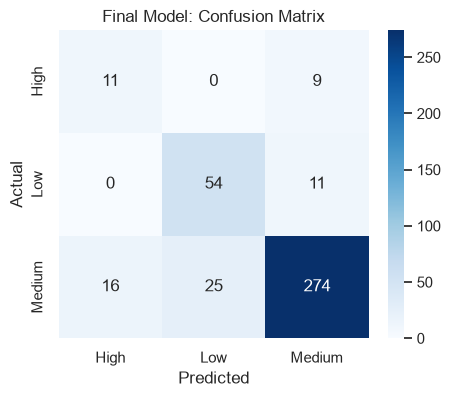

Test macro-F1: 0.706
Test High recall: 0.55


In [14]:
test_pred = final_model.predict(X_test)

print(classification_report(y_test, test_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Final Model: Confusion Matrix")
plt.show()

print("Test macro-F1:", round(f1_score(y_test, test_pred, average="macro"), 3))
print("Test High recall:", round(recall_score(y_test, test_pred, labels=[HIGH], average=None)[0], 3))

**Remember:** the test set has only ~20 High patients. One patient changes High recall by 5%.
So treat these numbers as an estimate, not an exact truth.

## 11. Better High-Risk Detection (Threshold Tuning)

In a health setting, **missing a High-risk person** is worse than a false alarm.
The model gives a probability for each class. We multiply the **High probability by a boost factor** before
choosing the class. A bigger boost catches more High cases but also creates more false alarms.

**Important:** we choose the boost factor using *out-of-fold predictions on the training data*,
**not** the test set. This keeps the test set honest.

In [15]:
# Out-of-fold probabilities on the training set
oof_proba = np.zeros((len(X_train), len(CLASSES)))
for tr, va in skf.split(X_train, y_train):
    w = compute_sample_weight("balanced", y_train[tr])
    m = XGBClassifier(**best_params, random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss")
    m.fit(X_train.iloc[tr], y_train[tr], sample_weight=w)
    oof_proba[va] = m.predict_proba(X_train.iloc[va])

def predict_with_boost(proba, boost):
    p = proba.copy()
    p[:, HIGH] *= boost
    return p.argmax(axis=1)

rows = []
for boost in [1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0]:
    pred = predict_with_boost(oof_proba, boost)
    rows.append({
        "Boost": boost,
        "High recall": recall_score(y_train, pred, labels=[HIGH], average=None)[0],
        "High precision": (pred[pred == HIGH] == y_train[pred == HIGH]).mean() if (pred == HIGH).any() else 0,
        "High F2": fbeta_score(y_train, pred, beta=2, labels=[HIGH], average=None)[0],
        "Macro-F1": f1_score(y_train, pred, average="macro"),
    })
boost_table = pd.DataFrame(rows)
boost_table.round(3)

,Boost,High recall,High precision,High F2,Macro-F1
0,1.00,0.732,0.526,0.679,0.733
1,1.25,0.756,0.466,0.672,0.719
2,1.50,0.780,0.430,0.671,0.710
3,2.00,0.780,0.352,0.627,0.681
4,2.50,0.805,0.316,0.615,0.667
5,3.00,0.829,0.293,0.607,0.657
6,4.00,0.829,0.260,0.576,0.639


**F2 score** values recall more than precision, which fits our goal. We pick the boost with the best High F2,
but we also check that macro-F1 does not fall too much.

In [16]:
best_boost = float(boost_table.loc[boost_table["High F2"].idxmax(), "Boost"])
print("Chosen boost factor:", best_boost)

test_proba = final_model.predict_proba(X_test)
tuned_pred = predict_with_boost(test_proba, best_boost)

print("\n--- Test results WITH threshold tuning ---")
print(classification_report(y_test, tuned_pred, target_names=CLASSES, digits=3))
print(pd.DataFrame(confusion_matrix(y_test, tuned_pred),
                   index=[f"Actual {c}" for c in CLASSES],
                   columns=[f"Pred {c}" for c in CLASSES]))

Chosen boost factor: 1.0

--- Test results WITH threshold tuning ---
              precision    recall  f1-score   support

        High      0.407     0.550     0.468        20
         Low      0.684     0.831     0.750        65
      Medium      0.932     0.870     0.900       315

    accuracy                          0.848       400
   macro avg      0.674     0.750     0.706       400
weighted avg      0.865     0.848     0.854       400

               Pred High  Pred Low  Pred Medium
Actual High           11         0            9
Actual Low             0        54           11
Actual Medium         16        25          274


Compare this with Section 10. If High recall went up a lot but High precision and macro-F1 dropped a lot,
you can choose a smaller boost. This is a **decision about trade-offs**, so write your choice and reason in your project report.

## 12. What Does the Model Use? (Feature Importance)

**Permutation importance:** shuffle one feature at a time and see how much the score drops.
A bigger drop means the model depends more on that feature.

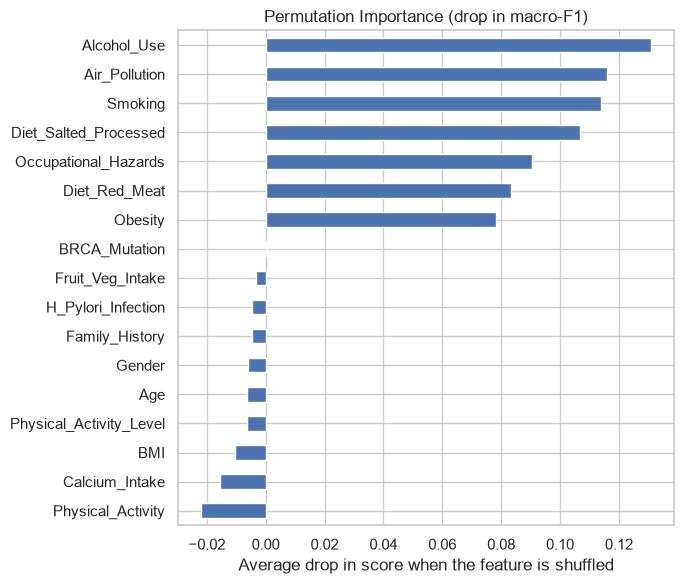

In [17]:
perm = permutation_importance(final_model, X_test, y_test, scoring="f1_macro",
                              n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

imp.plot(kind="barh", figsize=(7, 6), color="#4C72B0")
plt.title("Permutation Importance (drop in macro-F1)")
plt.xlabel("Average drop in score when the feature is shuffled")
plt.tight_layout()
plt.show()

These are the features the model relies on most. This shows what the **model** uses. It does not prove that
a feature **causes** cancer.

## 13. Save the Model for Deployment

We save **everything needed for prediction in one file**: the model, the label encoder, the feature order,
and the High boost factor. Nothing else is needed at prediction time.

In [18]:
bundle = {
    "model": final_model,
    "label_encoder": le,
    "feature_columns": list(X.columns),
    "classes": CLASSES,
    "high_boost": best_boost,
    "model_name": "XGBoost + class weights (Optuna tuned)",
}
joblib.dump(bundle, "cancer_risk_final_model.pkl")
print("Saved: cancer_risk_final_model.pkl")

Saved: cancer_risk_final_model.pkl


### 13.1 Reload and check that predictions match

In [19]:
loaded = joblib.load("cancer_risk_final_model.pkl")

def predict_risk(patient: dict, bundle=loaded):
    """Takes one patient as a dict, returns the risk level and class probabilities."""
    row = pd.DataFrame([patient])[bundle["feature_columns"]]
    proba = bundle["model"].predict_proba(row)
    boosted = proba.copy()
    boosted[:, bundle["classes"].index("High")] *= bundle["high_boost"]
    label = bundle["classes"][int(boosted.argmax(axis=1)[0])]
    return {"risk_level": label,
            "probabilities": {c: round(float(p), 3) for c, p in zip(bundle["classes"], proba[0])}}

# 1) Same predictions as before saving?
reloaded_pred = loaded["model"].predict_proba(X_test)
print("Predictions match after reload:", np.allclose(reloaded_pred, test_proba))

# 2) Try one real row from the test set
example = X_test.iloc[0].to_dict()
print("Example input :", example)
print("Prediction    :", predict_risk(example))
print("Actual label  :", CLASSES[y_test[0]])

Predictions match after reload: True
Example input : {'Age': 74.0, 'Gender': 0.0, 'Smoking': 5.0, 'Alcohol_Use': 5.0, 'Obesity': 8.0, 'Family_History': 0.0, 'Diet_Red_Meat': 8.0, 'Diet_Salted_Processed': 2.0, 'Fruit_Veg_Intake': 1.0, 'Physical_Activity': 2.0, 'Air_Pollution': 8.0, 'Occupational_Hazards': 5.0, 'BRCA_Mutation': 1.0, 'H_Pylori_Infection': 0.0, 'Calcium_Intake': 4.0, 'BMI': 30.5, 'Physical_Activity_Level': 1.0}
Prediction    : {'risk_level': 'Medium', 'probabilities': {'High': 0.157, 'Low': 0.021, 'Medium': 0.821}}
Actual label  : Medium


## 14. Conclusion and Limitations

**What we did right**
- Found and removed a leaky column (`Overall_Risk_Score`), so scores are honest.
- Compared models with repeated cross-validation, not one lucky split.
- Resampling and class weights were applied inside training folds only.
- Used macro-F1 and High recall instead of accuracy alone.
- Chose the High-risk threshold on training data and used the test set once.
- Saved a single, complete bundle that reloads and gives the same predictions.

**Limitations (write these honestly in your report)**
- The dataset looks synthetic, so real-world performance is unknown.
- Only ~20 High cases in the test set, so scores are noisy.
- `Risk_Level` appears to be derived from a score, so there may be a natural ceiling on accuracy.
- This is an educational model and **must not be used for medical decisions**.

**Ideas for the next step**
- Try one-hot encoded `Cancer_Type` as an extra feature.
- Add SHAP plots for per-patient explanations.
- Build the API / web app (FastAPI or Streamlit) using `cancer_risk_final_model.pkl` and `predict_risk`.

In [20]:
   import sklearn, xgboost, pandas, numpy, joblib
   print("pandas==" + pandas.__version__)
   print("numpy==" + numpy.__version__)
   print("scikit-learn==" + sklearn.__version__)
   print("xgboost==" + xgboost.__version__)
   print("joblib==" + joblib.__version__)


pandas==3.0.5
numpy==2.5.2
scikit-learn==1.9.1
xgboost==3.4.1
joblib==1.6.0
